#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df. Create Functions for the same
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart. 
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City. 

</pre>


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install plotly

In [3]:
cb = pd.read_csv('cust_bio.csv')
sp = pd.read_csv('sp.csv')
ca = pd.read_csv('cust_activity.csv')
orders = pd.read_csv('orders.csv')
cs = pd.read_csv('cust_sub.csv')

In [4]:
print(cb.shape)
print(sp.shape)
print(ca.shape)
print(orders.shape)
print(cs.shape)

(478, 3)
(6, 5)
(7500, 3)
(127, 4)
(51, 3)


In [9]:
print(cb.columns)
print(ca.columns)
print(orders.columns)
print(sp.columns)
print(cs.columns)

Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')


In [10]:
### Q1) Check null values and duplicates in each df. Create Functions for the same

In [11]:
def check_null_dup(data):
    dup = data.duplicated().sum()
    nv = data.isnull().sum()
    if dup == 0 and nv.sum() == 0:
        print('No Duplicates and No Null Values')
    else:
        return dup, nv

In [12]:
check_null_dup(cb)
check_null_dup(ca)
check_null_dup(cs)
check_null_dup(sp)
check_null_dup(orders)

No Duplicates and No Null Values
No Duplicates and No Null Values
No Duplicates and No Null Values
No Duplicates and No Null Values
No Duplicates and No Null Values


In [14]:
#### Q2) Find Count of Customers from each city and represent it on bar chart.

In [19]:
import plotly.express as px

In [18]:
q2 = cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


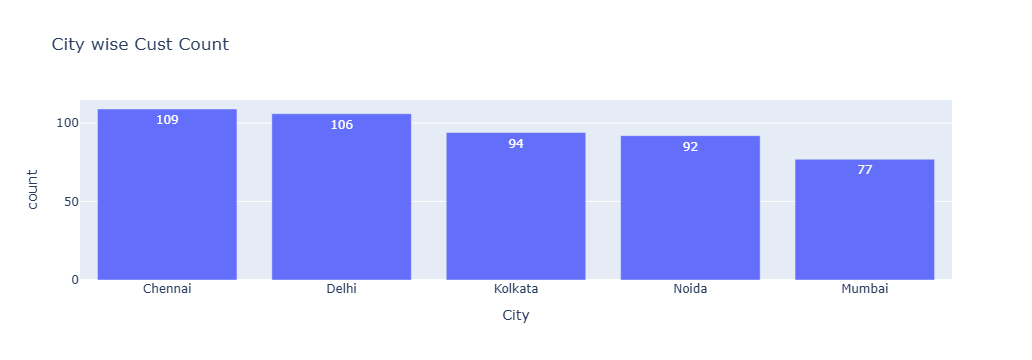

In [21]:
fig = px.bar(data_frame=q2,x='City',y='count',text='count',title='City wise Cust Count')
fig.show()

In [22]:
###Q3) Find Range Age wise count of cutsomers, represent it on pie chart. 

In [24]:
# cb.columns
cb['Age_Range'] = pd.cut(cb['Age'], bins = [19,23,27,31,35,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [25]:
q3 = cb['Age_Range'].value_counts().reset_index()
q3

,Age_Range,count
0,"(31, 35]",116
1,"(19, 23]",112
2,"(23, 27]",95
3,"(27, 31]",93
4,"(35, 39]",62


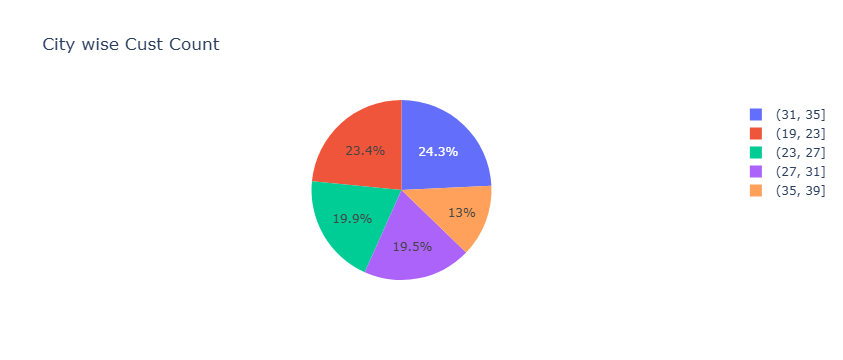

In [26]:
fig2 = px.pie(data_frame=q3,names='Age_Range',values ='count' ,title ='Age Range % distribution')
fig2.show()

In [27]:
###Q4) Find Count of each activity, represent it on bar chart

In [28]:
ca.columns

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')

In [29]:
q4 = ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


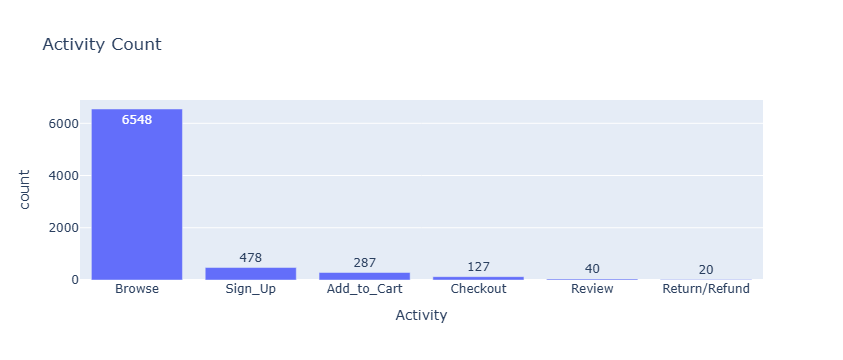

In [33]:
fig3 = px.bar(data_frame=q4,x='Activity',y='count',text='count',title='Activity Count')
fig3.show()

In [31]:
####Q5) Find order month wise total amount. Represent it on line chart.

In [34]:
print(orders.columns)
print(ca.columns)

Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Cust_ID', 'Activity', 'Date'], dtype='str')


In [42]:
ca['Date'] = pd.to_datetime(ca['Date'])

In [43]:
ca_cout = ca[ca['Activity']=='Checkout']
ca_cout.shape

(127, 3)

In [44]:
q5 = pd.merge(orders,ca_cout,on='Cust_ID')
q5['Order_Month'] = q5['Date'].dt.month
q5.head(3)

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Order_Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7


In [45]:
q5_ans = q5.groupby('Order_Month')['Amount'].sum().reset_index()
q5_ans

,Order_Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46
5,6,69580.07
6,7,80416.05
7,8,27227.29
8,9,34804.62
9,10,30298.38


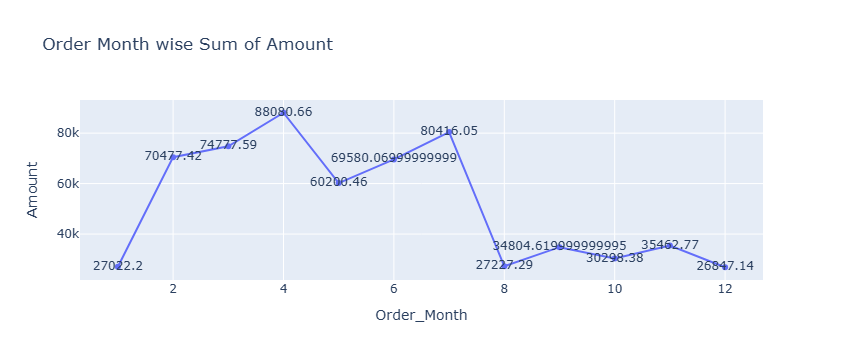

In [46]:
fig = px.line(data_frame=q5_ans,x='Order_Month',y='Amount',text='Amount',title='Order Month wise Sum of Amount')
fig.show()

In [47]:
####Q6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.

In [49]:
print(sp.columns)
print(cs.columns)

Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')


In [50]:
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [51]:
q6 = cs_sp.groupby('Plan_Var_ID')['Price'].sum().reset_index()
q6

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


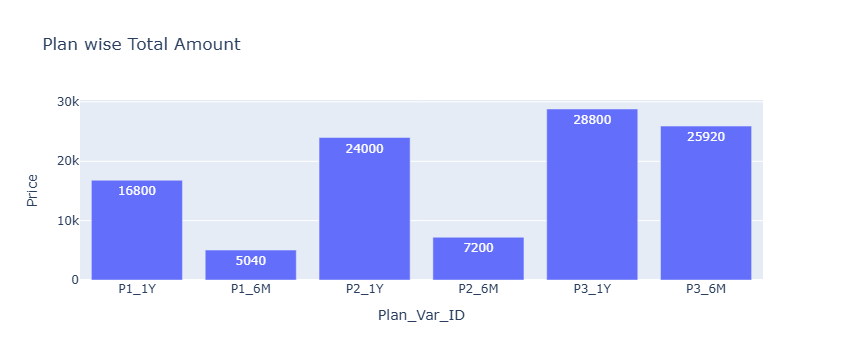

In [52]:
fig = px.bar(data_frame=q6, x='Plan_Var_ID',y='Price',text='Price',title='Plan wise Total Amount')
fig.show()

In [54]:
####Q7) City wise find total amount

In [57]:
# cb.columns cb,orders


Index(['Cust_ID', 'City', 'Age', 'Age_Range'], dtype='str')

In [58]:
###Q8) Find count of each payment mode, represent it on donut chart

In [60]:
orders.columns

Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')

In [62]:
q8 = orders['Payment_mode'].value_counts().reset_index()
q8

,Payment_mode,count
0,Net Banking,29
1,Debit Card,27
2,UPI,24
3,Credit_Card,24
4,COD,23


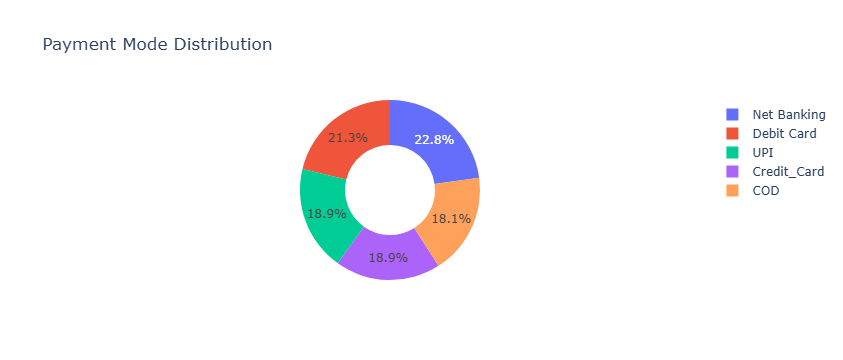

In [65]:
fig = px.pie(data_frame=q8,names='Payment_mode',values='count',hole=0.5,title='Payment Mode Distribution')
fig.show()

### Funnel Analysis

In [67]:
ca['Activity'].value_counts()

Activity
Browse           6548
Sign_Up           478
Add_to_Cart       287
Checkout          127
Review             40
Return/Refund      20
Name: count, dtype: int64

In [72]:
z1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='count')
z1.head(10)

,Cust_ID,Activity,count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10
5,CUS_123,Browse,10
6,CUS_124,Add_to_Cart,1
7,CUS_124,Browse,9
8,CUS_124,Sign_Up,1
9,CUS_125,Browse,9


In [87]:
funnel = z1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [88]:
funnel['Prev_Count'] = np.where(funnel['Activity']=='Return/Refund', funnel['count'].shift(2),
                               funnel['count'].shift(1))
funnel

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [89]:
funnel['Conversion%'] = round((funnel['count']/funnel['Prev_Count'])*100,2)
funnel = funnel.fillna(0)
funnel

,Activity,count,Prev_Count,Conversion%
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


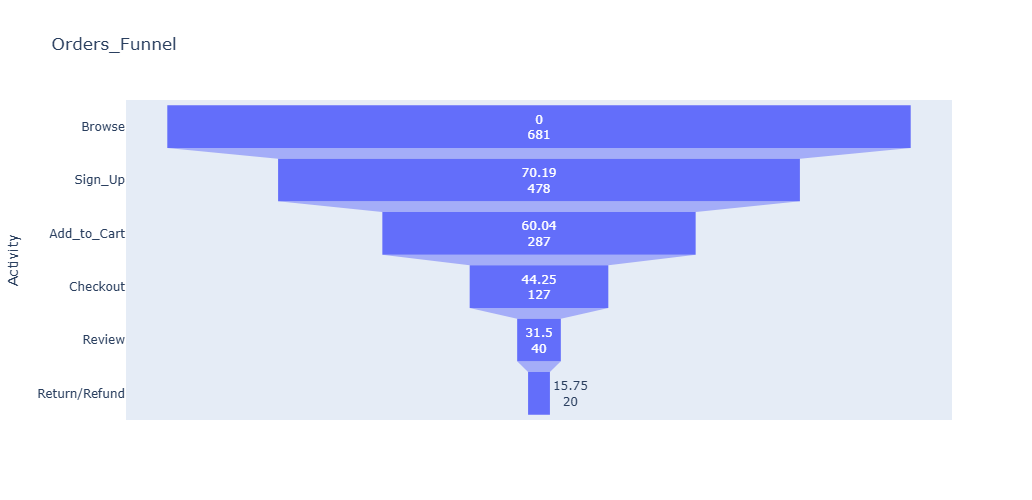

In [90]:
fig = px.funnel(data_frame=funnel, x='count',y='Activity',text='Conversion%',hover_data='count',
               title='Orders_Funnel',height=500)
fig.show()

In [91]:
####Q2) Find Customer wise count of days to transition from one stage of funnel to the next stage

In [96]:
ca.head(20)

,Cust_ID,Activity,Date
0,CUS_121,Sign_Up,2024-04-24
1,CUS_121,Browse,2024-04-27
2,CUS_121,Add_to_Cart,2024-04-27
3,CUS_121,Browse,2024-04-29
4,CUS_121,Browse,2024-04-30
5,CUS_121,Browse,2024-05-04
6,CUS_121,Checkout,2024-05-05
7,CUS_121,Browse,2024-05-07
8,CUS_121,Browse,2024-05-09
9,CUS_121,Browse,2024-05-10


In [99]:
pt1 = pd.pivot_table(data=ca, index='Cust_ID', columns='Activity', values='Date',aggfunc='min')
pt1.head(10)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [100]:
pt1['DD_Browse_2Signup'] = abs((pt1['Browse'] - pt1['Sign_Up']).dt.days)
pt1['DD_Add2Cart_2Browse'] = (pt1['Add_to_Cart'] - pt1['Browse']).dt.days
pt1['DD_Checkout_2Add2Cart'] = (pt1['Checkout'] - pt1['Add_to_Cart']).dt.days
pt1['DD_Review_2Checkout'] = (pt1['Review'] - pt1['Checkout']).dt.days
pt1['DD_Return/Refund_2Checkout'] = (pt1['Return/Refund'] - pt1['Checkout']).dt.days
pt1.head(10)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2Signup,DD_Add2Cart_2Browse,DD_Checkout_2Add2Cart,DD_Review_2Checkout,DD_Return/Refund_2Checkout
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,0.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,0.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27,1.0,NaN,NaN,NaN,NaN
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26,2.0,0.0,19.0,NaN,NaN
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21,1.0,0.0,11.0,NaN,NaN


In [111]:
pt2 = pt1.iloc[:,-5:]
pt2.head()

Activity,DD_Browse_2Signup,DD_Add2Cart_2Browse,DD_Checkout_2Add2Cart,DD_Review_2Checkout,DD_Return/Refund_2Checkout
Cust_ID,,,,,
CUS_121,3.0,0.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN
CUS_123,NaN,NaN,NaN,NaN,NaN
CUS_124,1.0,0.0,NaN,NaN,NaN
CUS_125,2.0,NaN,NaN,NaN,NaN


In [112]:
avg_dd = np.round(pt2.mean().values)
avg_dd

array([ 3.,  1., 14.,  3.,  3.])

In [113]:
# adding 0 as there is 0 DateDiff from Browse 2 Browse
avg_dd = [0] + list(avg_dd)
avg_dd

[0,
 np.float64(3.0),
 np.float64(1.0),
 np.float64(14.0),
 np.float64(3.0),
 np.float64(3.0)]

In [114]:
funnel['Avg_DayDiff'] = avg_dd
funnel

,Activity,count,Prev_Count,Conversion%,Avg_DayDiff
0,Browse,681,0.0,0.00,0.0
1,Sign_Up,478,681.0,70.19,3.0
2,Add_to_Cart,287,478.0,60.04,1.0
3,Checkout,127,287.0,44.25,14.0
4,Review,40,127.0,31.50,3.0
5,Return/Refund,20,127.0,15.75,3.0


In [123]:
funnel['Conversion%'] = funnel['Conversion%'].apply(lambda x : str(x) + '%')
funnel

,Activity,count,Prev_Count,Conversion%,Avg_DayDiff
0,Browse,681,0.0,0.0%%,0.0
1,Sign_Up,478,681.0,70.19%%,3.0
2,Add_to_Cart,287,478.0,60.04%%,1.0
3,Checkout,127,287.0,44.25%%,14.0
4,Review,40,127.0,31.5%%,3.0
5,Return/Refund,20,127.0,15.75%%,3.0


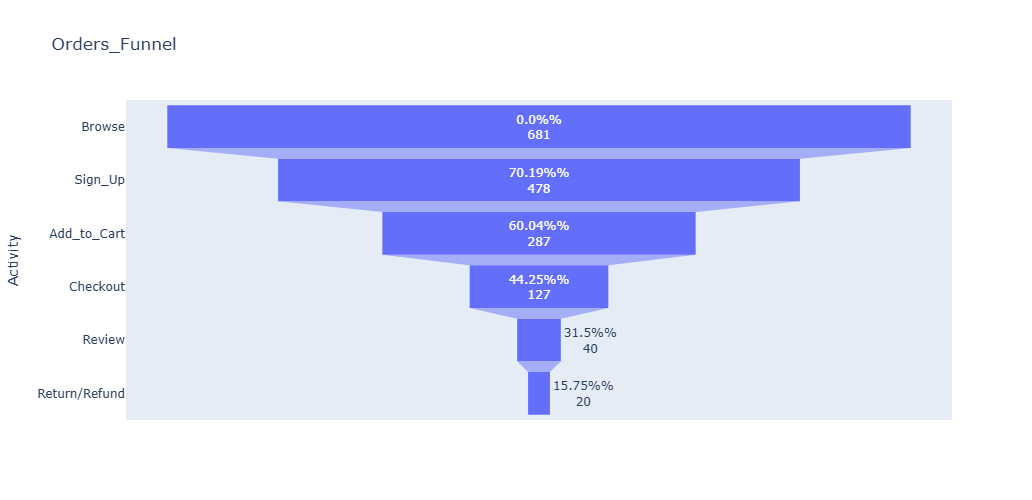

In [124]:
fig = px.funnel(data_frame=funnel, x='count',y='Activity',text='Conversion%',hover_data='Avg_DayDiff',
               title='Orders_Funnel',height=500)
fig.show()